In [237]:
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer
from sklearn.model_selection import KFold
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


In [238]:
filepath = os.path.join(os.path.abspath(".."), "data", "course_lead_scoring_2026.csv")
df = pd.read_csv(filepath)
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [239]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


In [240]:
null = (df.isnull().sum() > 0)
cat = df.columns[null & (df.dtypes == "str")]
nums = df.columns[null & (df.dtypes != "str")]
cat, nums

(Index(['lead_source', 'industry', 'employment_status', 'location'], dtype='str'),
 Index(['annual_income', 'lead_score'], dtype='str'))

In [241]:
df[cat] = df[cat].fillna('NA')
df[nums] = df[nums].fillna(0.0)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               5000 non-null   str    
 1   industry                  5000 non-null   str    
 2   employment_status         5000 non-null   str    
 3   location                  5000 non-null   str    
 4   annual_income             5000 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                5000 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


In [242]:
df_train_full, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_train_full, test_size=0.25, random_state=1)
df_train.shape, df_val.shape, df_test.shape

((3000, 9), (1000, 9), (1000, 9))

In [243]:
df_train_full = df_train_full.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values
df_train = df_train.drop(columns=["converted"])
df_val = df_val.drop(columns=["converted"])
df_test = df_test.drop(columns=["converted"])

In [244]:
nums = df_train.columns[df_train.dtypes != "str"]
for column in nums:
    auc = roc_auc_score(y_train, df_train[column])
    print(f"{column}: {auc}")

annual_income: 0.6081977776250831
number_of_courses_viewed: 0.7229894623989618
interaction_count: 0.7649203047563227
lead_score: 0.7882254810906102


In [245]:
model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000)
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train.to_dict(orient="records"))
X_val = dv.transform(df_val.to_dict(orient="records"))
model.fit(X_train, y_train)
y_pred = model.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred)
print(f"auc: {auc:.3}")

auc: 0.732


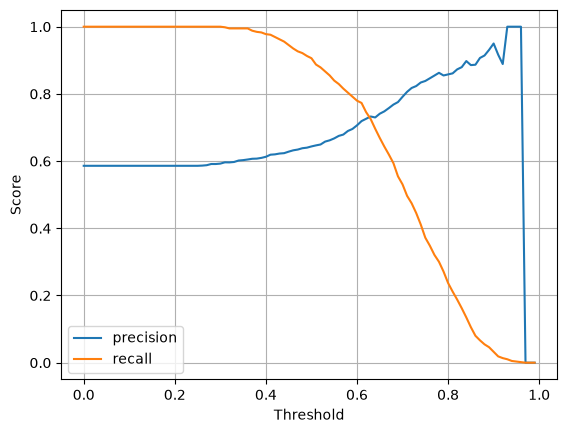

In [246]:
precision = [];
recall = [];
threshold = np.arange(0.0, 1.0, 0.01)
for t in threshold:
    precision.append(precision_score(y_val, (y_pred >= t).astype(int), zero_division=0))
    recall.append(recall_score(y_val, (y_pred >= t).astype(int), zero_division=0))

plt.plot(threshold, precision, label="precision")
plt.plot(threshold, recall, label="recall")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid()
plt.show()

In [247]:
precision = np.array(precision)
recall = np.array(recall)

In [248]:
valid = ~((precision == 0) & (recall == 0))
differences = np.abs(precision - recall)
differences[~valid] = np.inf
differences

array([0.414     , 0.414     , 0.414     , 0.414     , 0.414     ,
       0.414     , 0.414     , 0.414     , 0.414     , 0.414     ,
       0.414     , 0.414     , 0.414     , 0.414     , 0.414     ,
       0.414     , 0.414     , 0.414     , 0.414     , 0.414     ,
       0.414     , 0.414     , 0.414     , 0.414     , 0.414     ,
       0.414     , 0.41341341, 0.41223671, 0.4086781 , 0.4086781 ,
       0.40748231, 0.40196324, 0.39876603, 0.39754448, 0.39322936,
       0.39198499, 0.39010876, 0.38113637, 0.37727322, 0.37341134,
       0.36498148, 0.3570616 , 0.34919594, 0.33994078, 0.33202338,
       0.31727458, 0.30308899, 0.29227537, 0.28320383, 0.27301713,
       0.26250698, 0.24060584, 0.22940706, 0.20886311, 0.19312582,
       0.17201921, 0.15435154, 0.13672239, 0.11414958, 0.0961567 ,
       0.07352654, 0.05398992, 0.01982017, 0.00750265, 0.03362904,
       0.07207881, 0.10467116, 0.13837489, 0.17435527, 0.22104882,
       0.26063188, 0.30950715, 0.34324433, 0.37795136, 0.42264

In [249]:
best_idx = np.argmin(differences)
print("best_idx: ", best_idx)
print("Threshold: ", threshold[best_idx])
print("Precision: ", precision[best_idx])
print("Recall: ", recall[best_idx])
print("Absolute difference: ", differences[best_idx])

best_idx:  63
Threshold:  0.63
Precision:  0.7327586206896551
Recall:  0.7252559726962458
Absolute difference:  0.007502647993409384


In [250]:
def f1(p, r):
    return 2 * (p * r)/(p + r)
scores = []
for i in range(len(precision)):
    scores.append((threshold[i], f1(precision[i], recall[i])))
sorted(scores, key=lambda x: x[1], reverse=True)[0]

/tmp/nix-shell.WdwfLE/ipykernel_2817/1896239996.py:2: RuntimeWarning: invalid value encountered in scalar divide
  return 2 * (p * r)/(p + r)


(np.float64(0.41000000000000003), np.float64(0.7576158940397352))

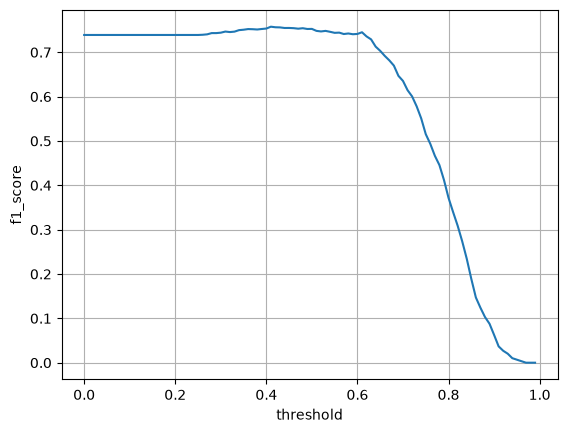

In [251]:
f1_scores = []
for t in threshold:
    f1_scores.append(f1_score(y_val, (y_pred >= t).astype(int), zero_division=0))
plt.plot(threshold, f1_scores)
plt.xlabel("threshold")
plt.ylabel("f1_score")
plt.grid()
plt.show()

In [252]:
best_index = np.argmax(f1_scores)
print(f"best_index: {best_index}")
print(f"threshold: {threshold[best_index]}")
print(f"f1_score: {f1_scores[best_index]}")

best_index: 41
threshold: 0.41000000000000003
f1_score: 0.7576158940397351


In [258]:
kf = KFold(n_splits=5, shuffle=True, random_state=1)
y = df_train_full.converted.values
X = df_train_full.drop(columns=["converted"])
scores = []
for train_index, val_index in kf.split(X):
    X_train, X_val = X.iloc[train_index], X.iloc[val_index]
    y_train, y_val = y[train_index], y[val_index]
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(X_train.to_dict(orient="records"))
    X_val = dv.transform(X_val.to_dict(orient="records"))
    model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000)
    model.fit(X_train, y_train)
    y_pred = model.predict_proba(X_val)[:, 1]
    score = roc_auc_score(y_val, y_pred)
    scores.append(score)
scores = np.array(scores)
std = np.std(scores)
print(f"scores: {scores}")
print(f"std: {round(std, 3)}")

scores: [0.7305601  0.72957261 0.73634281 0.74124547 0.72091386]
std: 0.007


In [261]:
for C in [0.000001, 0.001, 1]:
    kf = KFold(n_splits=5, shuffle=True, random_state=1)
    y = df_train_full.converted.values
    X = df_train_full.drop(columns=["converted"])
    scores = []   
    for train_index, val_index in kf.split(X):
        X_train, X_val = X.iloc[train_index], X.iloc[val_index]
        y_train, y_val = y[train_index], y[val_index]
        model = LogisticRegression(solver="liblinear", C=C, max_iter=1000)
        dv = DictVectorizer(sparse=False)
        X_train = dv.fit_transform(X_train.to_dict(orient="records"))
        X_val = dv.transform(X_val.to_dict(orient="records"))
        model.fit(X_train, y_train)
        y_pred = model.predict_proba(X_val)[:, 1]
        score = roc_auc_score(y_val, y_pred)
        scores.append(score)
    scores = np.array(scores)
    score_mean = round(scores.mean(), 3)
    std = round(np.std(scores), 3)
    print(f"C: {C}")
    print(f"score: {score_mean}")
    print(f"std: {std}")
    print("------------------------------------------------------------")

C: 1e-06
score: 0.617
std: 0.019
------------------------------------------------------------
C: 0.001
score: 0.749
std: 0.01
------------------------------------------------------------
C: 1
score: 0.732
std: 0.007
------------------------------------------------------------
